In [2]:
import pandas as pd
import numpy as np

In [3]:
df_final = pd.read_csv("../data/clean/ironhack_idol_df.csv")
df_final.head()

,track_id,track_name,track_popularity,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_total_tracks,album_type,track_duration_min,album_release_year,main_genre
0,2lWc1iJlz2NVcStV5fbtPG,Clouds,67,BUNT.,69.0,293734.0,['stutter house'],2ArRQNLxf9t0O0gvmG5Vsj,Clouds,1,single,2.646000,2023,electronic / edm
1,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),63,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),26,album,3.755467,2021,pop
2,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,72,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,16,album,2.641050,2021,pop
3,41zXlQxzTi6cGAjpOXyLYH,idontwannabeyouanymore,78,Billie Eilish,90.0,118692183.0,[],7fRrTyKvE4Skh93v97gtcU,dont smile at me,9,single,3.392817,2017,pop
4,13jRFAGT8qd6aBwtJySlUm,Allein Allein - BENNETT Remix,52,Alok,76.0,11247155.0,"['brazilian bass', 'electronic', 'slap house',...",1WKoDELzbFRR6UWNGh50LO,Allein Allein (feat. FREY) [BENNETT Remix],2,single,2.432950,2024,electronic / edm


In [4]:
# 3. Standard statistics and averages for Track Popularity per Genre
print("--- Track Popularity Statistics by Genre ---")
genre_popularity_stats = df_final.groupby('main_genre')['track_popularity'].agg(
    track_count='count',
    mean_popularity='mean',
    median_popularity='median',
    min_popularity='min',
    max_popularity='max',
    std_popularity='std'
).reset_index()

# Sort by mean popularity descending and filter out extremely rare genres if needed
genre_popularity_stats = genre_popularity_stats.sort_values(by='mean_popularity', ascending=False)

# Display top 15 genres by average track popularity
display(genre_popularity_stats.head(15))

--- Track Popularity Statistics by Genre ---


,main_genre,track_count,mean_popularity,median_popularity,min_popularity,max_popularity,std_popularity
5,latin,50,64.560000,70.0,1,87,20.127309
7,pop,1797,59.986644,65.0,0,100,21.157718
3,hip-hop / rap,768,58.416667,64.5,0,91,21.775453
8,r&b / soul,351,57.199430,62.0,0,91,22.147302
4,indie / alternative,249,55.630522,60.0,0,92,23.403199
1,country,103,51.359223,49.0,0,86,15.652385
2,electronic / edm,351,47.974359,50.0,0,92,22.857994
9,rock / metal,130,45.646154,50.0,0,86,24.211875
6,niche / unknown,1220,39.586066,40.0,0,94,24.233482
10,soundtrack,181,33.486188,37.0,0,71,16.901219


In [5]:
df_final["artist_popularity"] = df_final["artist_popularity"].astype(float)

In [6]:
multi_hit_artists = df_final["artist_name"].value_counts()
multi_hit_artists = multi_hit_artists[multi_hit_artists > 2]
type(multi_hit_artists)

pandas.core.series.Series

In [16]:
df_hit_artists = df_final[df_final["artist_name"].isin(multi_hit_artists.index)]
display(df_hit_artists)
display(df_hit_artists.shape)

,track_id,track_name,track_popularity,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_total_tracks,album_type,track_duration_min,album_release_year,main_genre
1,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),63,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),26,album,3.755467,2021,pop
2,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,72,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,16,album,2.641050,2021,pop
3,41zXlQxzTi6cGAjpOXyLYH,idontwannabeyouanymore,78,Billie Eilish,90.0,118692183.0,[],7fRrTyKvE4Skh93v97gtcU,dont smile at me,9,single,3.392817,2017,pop
4,13jRFAGT8qd6aBwtJySlUm,Allein Allein - BENNETT Remix,52,Alok,76.0,11247155.0,"['brazilian bass', 'electronic', 'slap house',...",1WKoDELzbFRR6UWNGh50LO,Allein Allein (feat. FREY) [BENNETT Remix],2,single,2.432950,2024,electronic / edm
6,3LtpKP5abr2qqjunvjlX5i,Doja,77,Central Cee,79.0,9666661.0,"['uk drill', 'drill', 'uk grime', 'grime']",6oECjagksATHu2UaclXrq1,Doja,1,single,1.623200,2022,hip-hop / rap
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5257,1qBXkDmnMZXaumaaxwmdYu,First Day At School,39,Carlos Rafael Rivera,48.0,20284.0,[],7Gdn94u4xTxoIpfq2rZci9,The Queen's Gambit (Music from the Netflix Lim...,38,album,1.215117,2020,classical / instrumental
5258,4y4spB9m0Q6026KfkAvy9Q,Lonely (with benny blanco),66,Justin Bieber,91.0,85050158.0,[],3P5WIUJO0Ots1lQx09TOxk,Lonely (with benny blanco),1,single,2.488283,2020,pop
5259,6GFrELGVKBXRcrTNkwjSfF,Body And Mind,54,girl in red,73.0,8771418.0,['bedroom pop'],69p42ovQdwmYPLUsAQpeNn,if i could make it go quiet,11,album,3.111200,2021,pop
5260,58VTP6KnZs12PcAj5rMJ4W,the fruits,65,Paris Paloma,66.0,786890.0,[],48ssTnnFOCIP17sRaFNqu1,the fruits,1,single,3.494967,2022,indie / alternative


(3658, 14)

In [8]:
df_target = df_final[(df_final["artist_popularity"] <= 65) & (df_final["artist_popularity"] >= 35)]
df_target.shape

(1508, 14)

In [9]:
# 4. Standard statistics and averages for Target Artist track popularity per Genre
print("--- Track Popularity Statistics by Genre for Artist Popularity Between 35 to 65 ---")
target_genre_popularity_stats = df_target.groupby('main_genre')['track_popularity'].agg(
    track_count='count',
    mean_popularity='mean',
    median_popularity='median',
    min_popularity='min',
    max_popularity='max',
    std_popularity='std'
).reset_index()

# Sort by mean popularity descending and filter out extremely rare genres if needed
target_genre_popularity_stats = target_genre_popularity_stats.sort_values(by='median_popularity', ascending=False)

# Display top 15 genres by average track popularity
display(target_genre_popularity_stats.head(15))

--- Track Popularity Statistics by Genre for Artist Popularity Between 35 to 65 ---


,main_genre,track_count,mean_popularity,median_popularity,min_popularity,max_popularity,std_popularity
8,r&b / soul,108,45.592593,51.0,0,76,20.506683
1,country,54,44.388889,47.0,0,71,12.258869
6,niche / unknown,654,42.680428,47.0,0,83,23.316525
3,hip-hop / rap,105,41.485714,46.0,0,77,19.946618
2,electronic / edm,161,40.403727,42.0,0,80,19.395998
4,indie / alternative,62,39.080645,40.5,0,80,20.250317
7,pop,107,38.654206,40.0,0,80,20.763313
10,soundtrack,161,33.149068,37.0,0,71,16.549249
0,classical / instrumental,58,28.758621,35.5,0,62,18.616452
9,rock / metal,34,32.705882,33.5,0,69,18.380704


In [10]:
# 5. Standard statistics and averages for Target Artist's by artist popularity per Genre
print("--- Artist Popularity Statistics by Genre for Artist Popularity Between 35 to 65 ---")
target_artist_popularity_stats = df_target.groupby('main_genre')['artist_popularity'].agg(
    artist_count='count',
    mean_popularity='mean',
    median_popularity='median',
    min_popularity='min',
    max_popularity='max',
    std_popularity='std'
).reset_index()

# Sort by mean popularity descending and filter out extremely rare genres if needed
target_artist_popularity_stats = target_artist_popularity_stats.sort_values(by='median_popularity', ascending=False)

# Display top 15 genres by average track popularity
display(target_artist_popularity_stats.head(15))

--- Artist Popularity Statistics by Genre for Artist Popularity Between 35 to 65 ---


,main_genre,artist_count,mean_popularity,median_popularity,min_popularity,max_popularity,std_popularity
3,hip-hop / rap,105,55.876190,60.0,35.0,65.0,8.136687
4,indie / alternative,62,58.435484,60.0,40.0,65.0,4.803076
10,soundtrack,161,54.298137,58.0,37.0,65.0,8.026398
2,electronic / edm,161,54.844720,57.0,36.0,65.0,7.498799
8,r&b / soul,108,54.055556,55.0,35.0,64.0,6.353795
7,pop,107,53.626168,54.0,38.0,65.0,8.618238
1,country,54,54.537037,53.5,47.0,65.0,6.962739
9,rock / metal,34,53.735294,53.0,40.0,65.0,6.273121
6,niche / unknown,654,50.776758,51.0,35.0,65.0,8.992204
5,latin,4,51.000000,49.0,41.0,65.0,10.066446


In [19]:
df_target_genres = df_final[df_final["main_genre"].isin(["hip-hop / rap", "indie / alternative", "electronic / edm", "r&b / soul", "pop", "country"])]
display(df_target_genres)
df_target_genres["main_genre"].value_counts(dropna=False)

,track_id,track_name,track_popularity,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_total_tracks,album_type,track_duration_min,album_release_year,main_genre
0,2lWc1iJlz2NVcStV5fbtPG,Clouds,67,BUNT.,69.0,293734.0,['stutter house'],2ArRQNLxf9t0O0gvmG5Vsj,Clouds,1,single,2.646000,2023,electronic / edm
1,1msEuwSBneBKpVCZQcFTsU,Forever & Always (Taylor’s Version),63,Taylor Swift,100.0,145396321.0,[],4hDok0OAJd57SGIT8xuWJH,Fearless (Taylor's Version),26,album,3.755467,2021,pop
2,7bcy34fBT2ap1L4bfPsl9q,I Didn't Change My Number,72,Billie Eilish,90.0,118692183.0,[],0JGOiO34nwfUdDrD612dOp,Happier Than Ever,16,album,2.641050,2021,pop
3,41zXlQxzTi6cGAjpOXyLYH,idontwannabeyouanymore,78,Billie Eilish,90.0,118692183.0,[],7fRrTyKvE4Skh93v97gtcU,dont smile at me,9,single,3.392817,2017,pop
4,13jRFAGT8qd6aBwtJySlUm,Allein Allein - BENNETT Remix,52,Alok,76.0,11247155.0,"['brazilian bass', 'electronic', 'slap house',...",1WKoDELzbFRR6UWNGh50LO,Allein Allein (feat. FREY) [BENNETT Remix],2,single,2.432950,2024,electronic / edm
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
5256,5poOKpYEoQFVltwAXi8yaE,Home,36,AURORA,72.0,4699258.0,"['norwegian pop', 'art pop']",69YLD3zIxQt55bHjVlhLTP,All My Demons Greeting Me As A Friend (Deluxe),20,album,3.546217,2016,pop
5258,4y4spB9m0Q6026KfkAvy9Q,Lonely (with benny blanco),66,Justin Bieber,91.0,85050158.0,[],3P5WIUJO0Ots1lQx09TOxk,Lonely (with benny blanco),1,single,2.488283,2020,pop
5259,6GFrELGVKBXRcrTNkwjSfF,Body And Mind,54,girl in red,73.0,8771418.0,['bedroom pop'],69p42ovQdwmYPLUsAQpeNn,if i could make it go quiet,11,album,3.111200,2021,pop
5260,58VTP6KnZs12PcAj5rMJ4W,the fruits,65,Paris Paloma,66.0,786890.0,[],48ssTnnFOCIP17sRaFNqu1,the fruits,1,single,3.494967,2022,indie / alternative


pop                    1797
hip-hop / rap           768
electronic / edm        351
r&b / soul              351
indie / alternative     249
country                 103
Name: main_genre, dtype: int64

In [20]:
genre_album_type = (
    df_target_genres.
        groupby(["main_genre", "album_type"])["track_popularity"]
        .agg(
            track_count="count",
            mean_popularity="mean",
            median_popularity="median"
)
    .sort_values(by="main_genre", ascending=False)
)

In [21]:
display(genre_album_type)

track_count  mean_popularity  \
main_genre          album_type                                  
r&b / soul          single               170        50.505882   
                    compilation           24        50.458333   
                    album                157        65.477707   
pop                 single               436        55.027523   
                    compilation           46        44.717391   
                    album               1315        62.165019   
indie / alternative compilation            8        35.750000   
                    single                81        51.000000   
                    album                160        58.968750   
hip-hop / rap       single               181        48.845304   
                    compilation            6        54.833333   
                    album                581        61.435456   
electronic / edm    single               264        47.734848   
                    compilation            2        38.500000   
                    album                 85        48.941176   
country             compilation           28        38.857143   
                    single                21        61.666667   
                    album                 54        53.833333   

                                 median_popularity  
main_genre          album_type                      
r&b / soul          single                    54.0  
                    compilation               48.0  
                    album                     67.0  
pop                 single                    65.0  
                    compilation               45.0  
                    album                     65.0  
indie / alternative compilation               42.5  
                    single                    58.0  
                    album                     62.0  
hip-hop / rap       single                    56.0  
                    compilation               52.0  
                    album                     66.0  
electronic / edm    single                    51.0  
                    compilation               38.5  
                    album                     48.0  
country             compilation               39.5  
                    single                    62.0  
                    album                     51.0

In [77]:
print("\n For Target Indie Artists from 2016 thru 2025 \n")
display(df_hit_artists[df_hit_artists["main_genre"]=="indie / alternative"].
        groupby(["artist_name"])["track_popularity"]
        .mean()
        .sort_values(ascending=False)
        .head(5)
       )

print("\n For Target Pop Artists from 2016 thru 2025 \n")
display(df_hit_artists[df_hit_artists["main_genre"]=="pop"].
        groupby(["artist_name"])["track_popularity"]
        .mean()
        .sort_values(ascending=False)
        .head(5)
       )

print("\n For Target R&B Artists from 2016 thru 2025 \n")
display(df_hit_artists[df_hit_artists["main_genre"]=="r&b / soul"].
        groupby(["artist_name"])["track_popularity"]
        .mean()
        .sort_values(ascending=False)
        .head(5)
       )


 For Target Indie Artists from 2016 thru 2025 



artist_name
sombr              79.666667
Mac DeMarco        79.000000
Tame Impala        72.833333
TV Girl            72.363636
Adrianne Lenker    71.750000
Name: track_popularity, dtype: float64


 For Target Pop Artists from 2016 thru 2025 



artist_name
HUNTR/X        93.750000
Olivia Dean    90.333333
KATSEYE        88.666667
Teddy Swims    84.666667
Alex Warren    83.400000
Name: track_popularity, dtype: float64


 For Target R&B Artists from 2016 thru 2025 



artist_name
Frank Ocean     84.000000
Chris Brown     76.666667
Clara La San    76.666667
Kali Uchis      74.142857
Kehlani         72.800000
Name: track_popularity, dtype: float64

In [49]:
display(df_final[df_final["artist_name"]=="Tame Impala"])

,track_id,track_name,track_popularity,artist_name,artist_popularity,artist_followers,artist_genres,album_id,album_name,album_total_tracks,album_type,track_duration_min,album_release_year,main_genre
618,1NXbNEAcPvY5G1xvfN57aA,Dracula,80,Tame Impala,84.0,9509731.0,"['neo-psychedelic', 'indie']",5WulAOx9ilWy1h8UGZ1gkI,Deadbeat,12,album,3.421800,2025,indie / alternative
984,709ZIqPHyFOpx2QdjmeWAM,Dracula,85,Tame Impala,84.0,9509731.0,"['neo-psychedelic', 'indie']",2kCjkEVRnLdEV5UOaQSAG4,Dracula,3,single,3.421800,2025,indie / alternative
1228,43evTNhnbi70nlOVZ8Q5sK,Journey To The Real World,44,Tame Impala,84.0,9509731.0,"['neo-psychedelic', 'indie']",0BaIaHcyBXuOWeM4Aas4EW,Barbie The Album,17,compilation,1.463783,2023,indie / alternative
1449,1Iw5iLfAwDvS6frI82gMoV,End Of Summer,72,Tame Impala,84.0,9509731.0,"['neo-psychedelic', 'indie']",3kgOKo0TlU22INB7U0Rqdj,End Of Summer,1,single,7.209433,2025,indie / alternative
2529,5hM5arv9KDbCHS0k9uqwjr,Borderline,83,Tame Impala,85.0,9517000.0,"['neo-psychedelic', 'indie']",31qVWUdRrlb8thMvts0yYL,The Slow Rush,12,album,3.963333,2020,indie / alternative
2805,0mO6oS60RST2sWmN2FKknP,One More Hour,73,Tame Impala,85.0,9517000.0,"['neo-psychedelic', 'indie']",31qVWUdRrlb8thMvts0yYL,The Slow Rush,12,album,7.209333,2020,indie / alternative


In [22]:
print("\n For Target Indie Artists from 2016 thru 2025 \n")
display(df_target[df_target["main_genre"]=="indie / alternative"].
        groupby(["artist_name"])["track_popularity"]
        .mean()
        .sort_values(ascending=False)
        .head(5)
       )

print("\n For Target Pop Artists from 2016 thru 2025 \n")
display(df_target[df_target["main_genre"]=="pop"].
        groupby(["artist_name"])["track_popularity"]
        .mean()
        .sort_values(ascending=False)
        .head(5)
       )

print("\n For Target R&B Artists from 2016 thru 2025 \n")
display(df_target[df_target["main_genre"]=="r&b / soul"].
        groupby(["artist_name"])["track_popularity"]
        .mean()
        .sort_values(ascending=False)
        .head(5)
       )


 For Target Indie Artists from 2016 thru 2025 



artist_name
Wolf Alice                      68.0
SOFIA ISELLA                    56.8
Drew Holcomb & The Neighbors    54.0
Rhiannon Giddens                52.5
Danheim                         52.0
Name: track_popularity, dtype: float64


 For Target Pop Artists from 2016 thru 2025 



artist_name
Loreen           80.0
Yot Club         77.0
SUICIDAL-IDOL    75.0
Astrid S         69.0
SALES            68.0
Name: track_popularity, dtype: float64


 For Target R&B Artists from 2016 thru 2025 



artist_name
Reed Wonder        74.000000
Victoria Monét     63.000000
Nicholas Bonnin    60.500000
Lucky Daye         60.333333
Cheyanne           59.000000
Name: track_popularity, dtype: float64

In [24]:
upcoming_artist_stats = df_target.groupby('artist_name')['track_popularity'].agg(
    track_count='count',
    mean_popularity='mean',
    median_popularity='median',
    min_popularity='min',
    max_popularity='max',
    std_popularity='std'
).reset_index()

In [28]:
display(upcoming_artist_stats.sort_values(by="track_count",ascending=False))

,artist_name,track_count,mean_popularity,median_popularity,min_popularity,max_popularity,std_popularity
358,K.Flay,24,39.208333,38.0,15,70,12.934548
141,ConKi,20,49.550000,53.5,0,65,17.635117
735,Unlike Pluto,17,35.058824,34.0,31,44,3.171565
764,Yasuharu Takanashi,16,35.187500,34.0,26,52,7.350454
83,Besomorph,14,31.071429,44.5,0,53,23.502747
...,...,...,...,...,...,...,...
342,Jonna Jinton,1,43.000000,43.0,43,43,NaN
344,Jordan Seigel,1,38.000000,38.0,38,38,NaN
346,Joris de Man,1,26.000000,26.0,26,26,NaN
347,Josh Homme,1,48.000000,48.0,48,48,NaN


In [39]:
upcoming_track_counts = upcoming_artist_stats["track_count"].sort_values(ascending=False).value_counts()
display(upcoming_track_counts)

1     606
2     123
3      36
4      23
6      10
5       7
12      6
7       5
9       5
11      5
8       2
10      2
14      2
20      1
13      1
16      1
17      1
24      1
Name: track_count, dtype: int64

<Axes: ylabel='Frequency'>

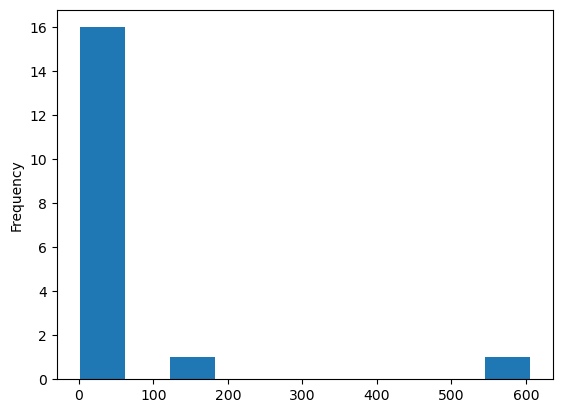

In [32]:
upcoming_track_counts.plot.hist()

<Axes: >

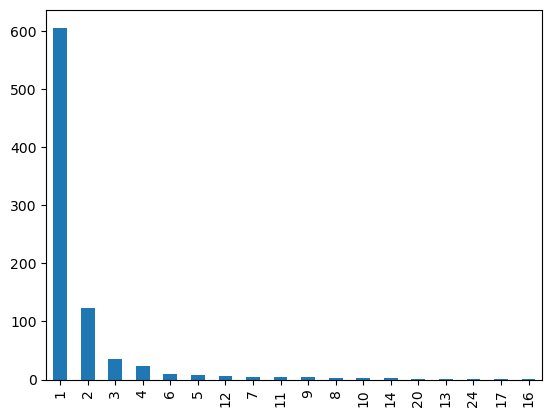

In [35]:
upcoming_track_counts.plot.bar()